The problem: An X-band pulse-Doppler radar (λ = 3 cm) tracks a maneuverable aircraft flying at 864 km/h. Identify the flight directions characterized by the angle /beta between the direction of the flight and the direction of radiation from the radar (all of them!) at which the aircraft will not be detectable against strong stationary clutter if the radar operates with the PRF=2 kHz.

Make a script to produce a simple movie (4:3 proportion) where on one side there is a panel 1, which represent the physical 2D space where the radar target makes a circular motion within the radar beam with constant velocity that is mention in the problem above. On other part of the movie screen there are two panels. On above panel 2 there is a plot where the x-axis represents the true radial velocity of the target. There are some marks that show n-th Doppler ambiguity intervals (limits and zeros). The y-axis is arbitrary, e.g. showing the small changes in target’s range. Target represented on this plot as a moving marker that are moving synchronously with the target on 1st panel. the 3rd panel include the similar plot but the x-axis limited by the Doppler umbiguity interval. The x-axis has to have two grids - radial velocity and orientation angle. Ask if you need more information.

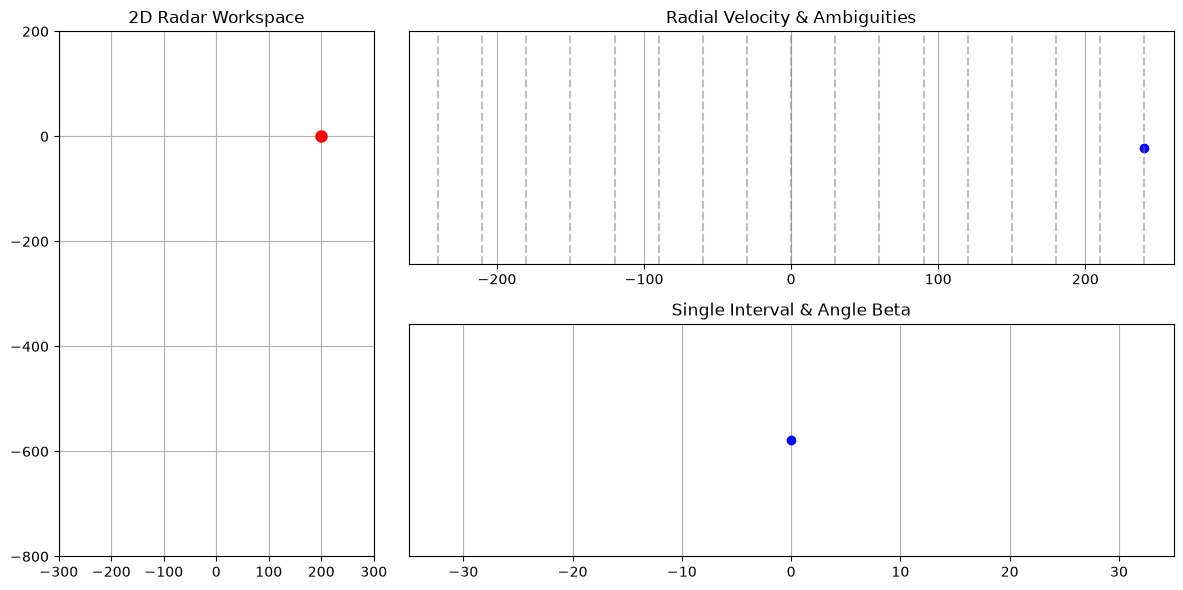

In [2]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

# --- Parameters ---
lam = 0.03  # Wavelength (m)
v = 240.0  # Speed (m/s, 864 km/h)
prf = 2000.0  # PRF (Hz)
v_blind = (prf * lam) / 2.0  # 30 m/s step

# --- Figure Setup (4:3 Ratio) ---
fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[0.3, 0.7], height_ratios=[1, 1])

# Panel 1: 2D Spatial Motion (Left, spans both rows)
ax1 = fig.add_subplot(gs[:, 0])
ax1.set_xlim(-300, 300)
ax1.set_ylim(-800, 200)
ax1.set_aspect("equal")
ax1.set_title("2D Radar Workspace")
ax1.grid(True)

# Panel 2: Radial Velocity & Ambiguity Intervals (Top Right)
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_xlim(-260, 260)
ax2.set_ylim(-1, 1)
ax2.set_title("Radial Velocity & Ambiguities")
ax2.set_yticks([])
ax2.grid(True)

# Panel 3: Single Interval with Dual Grids (Bottom Right)
ax3 = fig.add_subplot(gs[1, 1])
ax3.set_xlim(-35, 35)
ax3.set_ylim(-1, 1)
ax3.set_title("Single Interval & Angle Beta")
ax3.set_yticks([])
ax3.grid(True)

# --- Animation Elements ---
(target_dot,) = ax1.plot([], [], "ro", markersize=8)
(marker2,) = ax2.plot([], [], "bo", markersize=6)
(marker3,) = ax3.plot([], [], "bo", markersize=6)

# Draw blind speed marks on Panel 2
for n in range(-8, 9):
    ax2.axvline(n * v_blind, color="gray", linestyle="--", alpha=0.5)

# --- Animation Update ---
def update(frame):
  theta = 2 * np.pi * frame / 100.0
  x = 200 * np.cos(theta)
  y = 200 * np.sin(theta)

  # Calculate true radial velocity based on angle beta
  # Let target heading rotate, making beta change dynamically
  beta = theta
  vr = v * np.cos(beta)

  # Update positions
  target_dot.set_data([x], [y])
  marker2.set_data([vr], [0])

  # Wrap into single ambiguity interval for Panel 3
  vr_wrapped = ((vr + v_blind / 2) % v_blind) - v_blind / 2
  marker3.set_data([vr_wrapped], [0])

  return target_dot, marker2, marker3


ani = animation.FuncAnimation(fig, update, frames=100, interval=50, blit=True)
plt.tight_layout()
plt.show()